# TMDB Movie Data Analysis using Spark and PySpark
**By:** Molo Munyansanga

---

## Project Overview
This project builds a movie data analysis pipeline using Apache Spark (PySpark): fetching movie data from the TMDB API, cleaning and transforming it, and calculating key performance indicators (KPIs).

**How this notebook is organized:** the code for each step lives in the `src/` folder (`fetch.py`, `clean.py`, `analysis.py`, `visualize.py`). This notebook imports those functions and walks through the results step by step. To run the whole pipeline without the notebook, run `python main.py` from the project folder.

**How Spark runs this code:** Spark uses *lazy evaluation*. Transformations such as `filter()`, `withColumn()` or `groupBy()` don't compute anything; they add a step to a plan. Spark only runs the plan when an *action* needs a result, such as `show()`, `count()` or `toPandas()`. This lets Spark optimize the whole plan at once instead of running each step separately.

### Setup

In [1]:
# Let the notebook find the src/ folder (it is one level above this notebook)
import sys
sys.path.append("..")

from functools import reduce

from pyspark.sql import functions as F

from src import fetch, clean, analysis, visualize
from src.config import NUMERIC_COLUMNS
from src.spark_session import get_spark

spark = get_spark()

# Display Spark DataFrames as tables in the notebook (instead of calling .show())
spark.conf.set("spark.sql.repl.eagerEval.enabled", True)
spark.conf.set("spark.sql.repl.eagerEval.truncate", 60)

print(f"Spark {spark.version}")

Spark 4.3.0


## Project Steps
### Step 1: Fetch Movie Data from API
- Choose a movie database API (e.g., TMDb)
- Fetch movies with the following IDs:

```python
movie_id = [
    0, 299534, 19995, 140607, 299536, 597, 135397,
    420818, 24428, 168259, 99861, 284054, 12445,
    181808, 330457, 351286, 109445, 321612, 260513
]
```
- Store the data as a DataFrame

`fetch.load_or_fetch()` loads the saved raw data from `data/raw/movies_raw.jsonl` if it exists. Otherwise it fetches the movies from the API and saves them. Movie ID `0` doesn't exist on TMDB, so the API returns an error for it and it is skipped.

The raw data is saved as **JSON Lines** (one movie per line), the format Spark reads natively, and read with an explicit schema (`src/schemas.py`) instead of letting Spark guess the column types.

In [2]:
# Use refresh=True to fetch fresh data from the API instead of the saved file
raw_df = fetch.load_or_fetch(spark)
print(f"{raw_df.count()} rows, {len(raw_df.columns)} columns")

Loading saved raw data...
18 rows, 27 columns


The schema shows how the API organizes the data: simple columns (numbers and text), *structs* (one nested object, e.g. `belongs_to_collection`) and *arrays of structs* (lists of objects, e.g. `genres` or `credits.cast`).

In [3]:
raw_df.printSchema()

root
 |-- adult: boolean (nullable = true)
 |-- backdrop_path: string (nullable = true)
 |-- belongs_to_collection: struct (nullable = true)
 |    |-- id: long (nullable = true)
 |    |-- name: string (nullable = true)
 |    |-- poster_path: string (nullable = true)
 |    |-- backdrop_path: string (nullable = true)
 |-- budget: long (nullable = true)
 |-- genres: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- id: long (nullable = true)
 |    |    |-- name: string (nullable = true)
 |-- homepage: string (nullable = true)
 |-- id: long (nullable = true)
 |-- imdb_id: string (nullable = true)
 |-- origin_country: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- original_language: string (nullable = true)
 |-- original_title: string (nullable = true)
 |-- overview: string (nullable = true)
 |-- popularity: double (nullable = true)
 |-- poster_path: string (nullable = true)
 |-- production_companies: array (nullable = true)

In [4]:
raw_df.select("id", "title", "release_date", "budget", "revenue", "status").limit(5)

id,title,release_date,budget,revenue,status
299534,Avengers: Endgame,2019-04-24,356000000,2942186933,Released
19995,Avatar,2009-12-16,237000000,2923706026,Released
140607,Star Wars: The Force Awakens,2015-12-15,245000000,2068223624,Released
299536,Avengers: Infinity War,2018-04-25,300000000,2052415039,Released
597,Titanic,1997-12-18,200000000,2264162353,Released


### Step 2: Data Cleaning and Preprocessing
Each cleaning function takes a Spark DataFrame and returns a new one. Spark DataFrames can't be changed in place, so every step creates a new DataFrame (and, because of lazy evaluation, only adds a step to the plan).

#### Data Preparation & Cleaning
1. Drop irrelevant columns: `['adult', 'imdb_id', 'original_title', 'video', 'homepage']`

In [5]:
df = clean.drop_irrelevant_columns(raw_df)
df.columns

['backdrop_path',
 'belongs_to_collection',
 'budget',
 'genres',
 'id',
 'origin_country',
 'original_language',
 'overview',
 'popularity',
 'poster_path',
 'production_companies',
 'production_countries',
 'release_date',
 'revenue',
 'runtime',
 'spoken_languages',
 'status',
 'tagline',
 'title',
 'vote_average',
 'vote_count',
 'credits']

2. Evaluate JSON-like columns: `['belongs_to_collection', 'genres', 'production_countries', 'production_companies', 'spoken_languages']`
3. Extract and clean key data points:
    - Collection name (`belongs_to_collection`)

In [6]:
# What the column looks like before cleaning: a struct with the collection's details
df.select("title", "belongs_to_collection").limit(3)

title,belongs_to_collection
Avengers: Endgame,"{86311, The Avengers Collection, /yFSIUVTCvgYrpalUktulvk3..."
Avatar,"{87096, Avatar Collection, /3C5brXxnBxfkeKWwA1Fh4xvy4wr.j..."
Star Wars: The Force Awakens,"{10, Star Wars Collection, /pWVLFh4OuejTpUaDQbB1C4zoS2p.j..."


In [7]:
df = clean.extract_collection(df)
df.select("title", "belongs_to_collection").limit(5)

title,belongs_to_collection
Avengers: Endgame,The Avengers Collection
Avatar,Avatar Collection
Star Wars: The Force Awakens,Star Wars Collection
Avengers: Infinity War,The Avengers Collection
Titanic,NULL


- Credits (`credits`)

Clean the column into the names of the cast and the director(s), and count the size of the cast and crew. Directors are found with Spark's `filter()` function, which keeps only the crew members whose job is `"Director"`.

In [8]:
df = clean.extract_credits(df)
df.select("title", "cast", "cast_size", "director", "crew_size").limit(5)

title,cast,cast_size,director,crew_size
Avengers: Endgame,Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chris Hemswort...,103,Joe Russo|Anthony Russo,614
Avatar,Sam Worthington|Zoe Saldaña|Sigourney Weaver|Stephen Lang...,68,James Cameron,999
Star Wars: The Force Awakens,Daisy Ridley|John Boyega|Oscar Isaac|Adam Driver|Carrie F...,99,J.J. Abrams,270
Avengers: Infinity War,Robert Downey Jr.|Chris Evans|Chris Hemsworth|Josh Brolin...,69,Anthony Russo|Joe Russo,740
Titanic,Leonardo DiCaprio|Kate Winslet|Billy Zane|Kathy Bates|Fra...,116,James Cameron,272


- Genre names (`genres` → separate multiple genres with `|`)
- Spoken languages (`spoken_languages` → separate with `|`)
- Production countries (`production_countries` → separate with `|`)
- Production companies (`production_companies` → separate with `|`)

In [9]:
# What the column looks like before cleaning: an array of structs
df.select("title", "production_countries").limit(3)

title,production_countries
Avengers: Endgame,"[{US, United States of America}]"
Avatar,"[{US, United States of America}, {GB, United Kingdom}]"
Star Wars: The Force Awakens,"[{US, United States of America}]"


In [10]:
df = clean.extract_names(df)
df.select("genres", "spoken_languages", "production_countries", "production_companies").limit(5)

genres,spoken_languages,production_countries,production_companies
Adventure|Science Fiction|Action,English|日本語|,United States of America,Marvel Studios
Science Fiction|Action|Adventure,English|Español,United States of America|United Kingdom,Dune Entertainment|Lightstorm Entertainment|20th Century ...
Adventure|Action|Science Fiction,English,United States of America,Lucasfilm Ltd.|Bad Robot
Adventure|Action|Science Fiction,English|,United States of America,Marvel Studios
Drama|Romance,English|Français|Deutsch|svenska|Italiano|Pусский,United States of America,Paramount Pictures|20th Century Fox|Lightstorm Entertainment


4. Inspect extracted columns using `value_counts()` to identify anomalies

Spark has no `value_counts()`, so `clean.value_counts()` builds it from `groupBy().count()`. For the `|`-separated columns, `split_pipes=True` counts each item separately (e.g. `Action|Adventure` counts once for Action and once for Adventure).

In [11]:
clean.value_counts(df, "belongs_to_collection").show(truncate=False)
for col in ["genres", "spoken_languages", "production_countries", "production_companies"]:
    clean.value_counts(df, col, split_pipes=True).show(truncate=False)

+-----------------------------------+-----+
|belongs_to_collection              |count|
+-----------------------------------+-----+
|The Avengers Collection            |4    |
|NULL                               |2    |
|Frozen Collection                  |2    |
|Jurassic Park Collection           |2    |
|Star Wars Collection               |2    |
|Avatar Collection                  |1    |
|Black Panther Collection           |1    |
|Harry Potter Collection            |1    |
|The Fast and the Furious Collection|1    |
|The Incredibles Collection         |1    |
|The Lion King (Reboot) Collection  |1    |
+-----------------------------------+-----+

+---------------+-----+
|genres         |count|
+---------------+-----+
|Adventure      |15   |
|Action         |10   |
|Science Fiction|10   |
|Family         |5    |
|Animation      |4    |
|Fantasy        |4    |
|Thriller       |3    |
|Drama          |2    |
|Romance        |2    |
|Comedy         |1    |
|Crime          |1    |
+--

#### Handling Missing & Incorrect Data
5. Convert column datatypes:
    - `'budget'`, `'id'`, `'popularity'` → Numeric (set invalid values to null)
    - `'release_date'` → Convert to a date

Spark 4 runs in *ANSI mode* by default, where a plain `cast()` or `to_date()` stops the whole job with an error if it meets an invalid value. The cleaning code uses `try_cast()` and `try_to_date()` instead, which return null for invalid values, like Pandas' `errors="coerce"`.

In [12]:
df = clean.convert_types(df)
df.select("budget", "id", "popularity", "release_date").dtypes

[('budget', 'bigint'),
 ('id', 'bigint'),
 ('popularity', 'double'),
 ('release_date', 'date')]

**Observation:** `budget`, `id` and `popularity` were already numeric, because the schema read them with the right types, so the conversion doesn't change them. `release_date` is now a date.

6. Replace unrealistic values:
    - Budget / Revenue / Runtime = `0` → Replace with null
    - Movies with `vote_count = 0` → their `vote_average` is set to null
    - `'overview'` and `'tagline'` → Replace known placeholders (e.g., `'No Data'`) with null

In [13]:
# Check how many values will be affected before replacing them (all counted in one pass)
def count_if(condition):
    return F.sum(condition.cast("int"))

df.select(
    count_if(F.col("budget") == 0).alias("budget_0"),
    count_if(F.col("revenue") == 0).alias("revenue_0"),
    count_if(F.col("runtime") == 0).alias("runtime_0"),
    count_if(F.col("vote_count") == 0).alias("vote_count_0"),
    count_if(F.col("overview").isin("No Data", "")).alias("overview_placeholders"),
    count_if(F.col("tagline").isin("No Data", "")).alias("tagline_placeholders"),
)

budget_0,revenue_0,runtime_0,vote_count_0,overview_placeholders,tagline_placeholders
0,0,0,0,0,0


In [14]:
df = clean.replace_unrealistic_values(df)

**Observation:** There don't appear to be unrealistic values among these columns, so the replacement doesn't change anything in this dataset.

- Convert `'budget'` and `'revenue'` to million USD

In [15]:
df = clean.convert_to_millions(df)
df.select("title", "budget_musd", "revenue_musd").limit(5)

title,budget_musd,revenue_musd
Avengers: Endgame,356.0,2942.19
Avatar,237.0,2923.71
Star Wars: The Force Awakens,245.0,2068.22
Avengers: Infinity War,300.0,2052.42
Titanic,200.0,2264.16


7. Remove duplicates and drop rows with unknown `'id'` or `'title'`
8. Keep only rows where at least 10 columns have non-null values

In [16]:
# Look at the rows that have null values before removing anything
any_null = reduce(lambda a, b: a | b, [F.col(c).isNull() for c in df.columns])
rows_with_nulls = df.filter(any_null)
print("Rows with at least one null:", rows_with_nulls.count())
rows_with_nulls.select("id", "title", "belongs_to_collection")

Rows with at least one null: 2


id,title,belongs_to_collection
597,Titanic,NULL
321612,Beauty and the Beast,NULL


In [17]:
rows_before = df.count()
df = clean.remove_bad_rows(df)
print("Rows removed:", rows_before - df.count())

Rows removed: 0


**Observation:** There are no duplicates or missing ids/titles, and the rows with null values still have more than 10 non-null columns, so all rows are kept.

9. Filter to include only `'Released'` movies, then drop `'status'`

In [18]:
clean.value_counts(df, "status")

status,count
Released,18


In [19]:
df = clean.filter_released(df)

#### Reorder & Finalize DataFrame
10. Reorder columns
11. Reset index

Spark DataFrames don't have a row index like Pandas does, so there is no index to reset. Only the column order is set.

In [20]:
df = clean.reorder_columns(df)

# Keep the clean data in memory: every following step reuses it, and without
# cache() Spark would redo all the cleaning steps for each one
df = df.cache()
df.limit(5)

id,title,tagline,release_date,genres,belongs_to_collection,original_language,budget_musd,revenue_musd,production_companies,production_countries,vote_count,vote_average,popularity,runtime,overview,spoken_languages,poster_path,cast,cast_size,director,crew_size
168259,Furious 7,Vengeance hits home.,2015-04-01,Action|Crime|Thriller,The Fast and the Furious Collection,en,190.0,1515.4,Original Film|One Race|Universal Pictures,United States of America,11614,7.207,15.2039,138,Deckard Shaw seeks revenge against Dominic Toretto and hi...,العربية|English|Español|ภาษาไทย,/wurKlC3VKUgcfsn0K51MJYEleS2.jpg,Vin Diesel|Paul Walker|Dwayne Johnson|Michelle Rodriguez|...,50,James Wan,239
284054,Black Panther,Long live the king.,2018-02-13,Action|Adventure|Science Fiction,Black Panther Collection,en,200.0,1349.93,Marvel Studios,United States of America,24183,7.36,20.0998,135,"King T'Challa returns home to the reclusive, technologica...",English|한국어/조선말|Kiswahili|,/uxzzxijgPIY7slzFvMotPv8wjKA.jpg,Chadwick Boseman|Michael B. Jordan|Lupita Nyong'o|Danai G...,67,Ryan Coogler,588
299534,Avengers: Endgame,Avenge the fallen.,2019-04-24,Adventure|Science Fiction|Action,The Avengers Collection,en,356.0,2942.19,Marvel Studios,United States of America,29199,8.247,68.2804,181,"After the devastating events of Avengers: Infinity War, t...",English|日本語|,/jtDv3lCnST0fZRvdYFwR5CVwK2x.jpg,Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chris Hemswort...,103,Joe Russo|Anthony Russo,614
351286,Jurassic World: Fallen Kingdom,The park is gone.,2018-06-06,Adventure|Science Fiction|Thriller,Jurassic Park Collection,en,170.0,1310.47,Amblin Entertainment|Universal Pictures,United States of America,13135,6.52,14.622,129,"Three years after Jurassic World was destroyed, Isla Nubl...",English|Pусский,/x2Us3jR6ToMJjbcPbLimYoxf6xr.jpg,Chris Pratt|Bryce Dallas Howard|Rafe Spall|Justice Smith|...,41,J. A. Bayona,394
19995,Avatar,Enter the world of Pandora.,2009-12-16,Science Fiction|Action|Adventure,Avatar Collection,en,237.0,2923.71,Dune Entertainment|Lightstorm Entertainment|20th Century ...,United States of America|United Kingdom,34952,7.611,36.4465,162,"In the 22nd century, a paraplegic Marine is dispatched to...",English|Español,/gKY6q7SjCkAU6FqvqWybDYgUKIF.jpg,Sam Worthington|Zoe Saldaña|Sigourney Weaver|Stephen Lang...,68,James Cameron,999


In [21]:
# Save the clean data to data/processed/movies_clean.parquet
clean.save_clean_data(df)

Saved clean data...


**Note:** all the steps above can also be run in one line with `df = clean.clean_data(raw_df)`. That's what `main.py` does.

#### Before vs. After Cleaning
A quick summary of what the cleaning changed.

In [22]:
clean.compare_before_after(raw_df, df)

Metric,Before,After
Rows,18,18
Columns,27,22
Missing values (total),2,2
Duplicate ids,0,0


In [23]:
# Missing values per column after cleaning
clean.missing_values(df)

column,missing
belongs_to_collection,2


**Observation:** Only the column `belongs_to_collection` is empty, for the 2 standalone movies, which is expected.

### Exploratory Data Analysis (EDA)
Before calculating the KPIs, explore the clean data to understand what the dataset looks like.

#### Summary statistics

In [24]:
# Take a look at the summary statistics of the raw data:
clean.summary_statistics(raw_df, ["budget", "revenue", "vote_count", "vote_average", "popularity", "runtime"])

,budget,revenue,vote_count,vote_average,popularity,runtime
summary,,,,,,
count,1.800000e+01,1.800000e+01,18.00,18.00,18.00,18.00
mean,2.137778e+08,1.699857e+09,21808.67,7.40,27.80,138.00
stddev,6.195972e+07,5.395974e+08,8776.42,0.53,15.91,23.85
min,1.250000e+08,1.243226e+09,10555.00,6.52,13.97,102.00
max,3.560000e+08,2.942187e+09,40248.00,8.25,68.28,194.00


Now, let's take a look at the summary statistics of the cleaned data:

In [25]:
clean.summary_statistics(df, NUMERIC_COLUMNS)

,budget_musd,revenue_musd,vote_count,vote_average,popularity,runtime
summary,,,,,,
count,18.00,18.00,18.00,18.00,18.00,18.00
mean,213.78,1699.86,21808.67,7.40,27.80,138.00
stddev,61.96,539.60,8776.42,0.53,15.91,23.85
min,125.00,1243.23,10555.00,6.52,13.97,102.00
max,356.00,2942.19,40248.00,8.25,68.28,194.00


**Observation:** Every movie in this dataset is a major blockbuster. Revenues range from about \$1.24 billion (*Incredibles 2*) to \$2.94 billion (*Avengers: Endgame*), and budgets from \$125 million to \$356 million. Ratings fall in a narrow band between 6.52 and 8.25. Any conclusions from this analysis apply to top-grossing movies, not movies in general.

#### Distributions of key columns

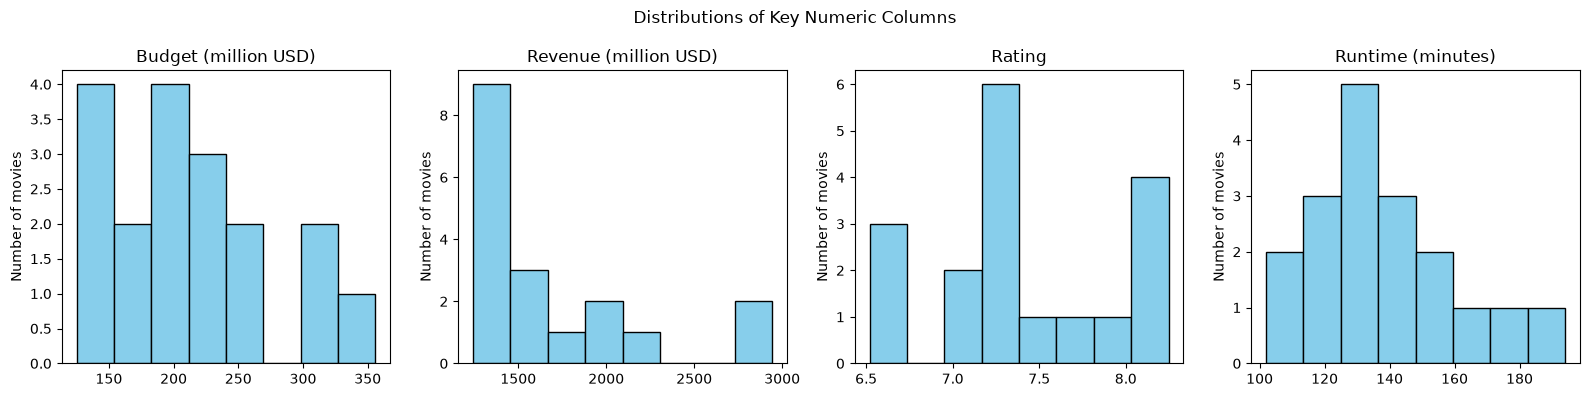

In [26]:
visualize.plot_distributions(df)

**Observation:** Revenue is right-skewed, with half the movies (9) earning between \$1.2B and \$1.45B and two outliers near \$2.9B. Most movies are rated between 7.2 and 7.4 and run 120–140 minutes.

#### Genres

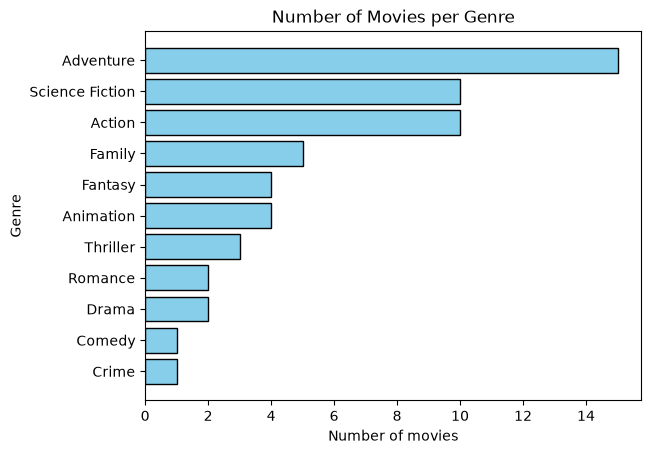

In [27]:
visualize.plot_genre_counts(df)

**Observation:** Adventure is the most common genre (15 of 18 movies), followed by Action and Science Fiction (10 each), while Comedy and Crime appear only once.

#### Release years

In [28]:
df.groupBy(F.year("release_date").alias("release_year")).count().orderBy("release_year")

release_year,count
1997,1
2009,1
2011,1
2012,1
2013,1
2015,4
2017,2
2018,4
2019,3


**Observation:** Apart from *Titanic* (1997) and *Avatar* (2009), every movie was released between 2011 and 2019, with none in 2014 or 2016. 2015 and 2018 have the most releases (4 each), so the dataset is mostly recent releases.

#### Franchise vs. standalone count

In [29]:
movie_type = F.when(F.col("belongs_to_collection").isNotNull(), "Franchise").otherwise("Standalone")
df.groupBy(movie_type.alias("movie_type")).count()

movie_type,count
Franchise,16
Standalone,2


**Observation:** 16 of the 18 movies belong to a franchise. Only *Titanic* and *Beauty and the Beast* are standalone, so the franchise vs. standalone comparison later is based on just 2 standalone movies.

#### Correlations between numeric columns
The correlations are computed by Spark's machine learning library (`pyspark.ml.stat.Correlation`) in a single pass over the data.

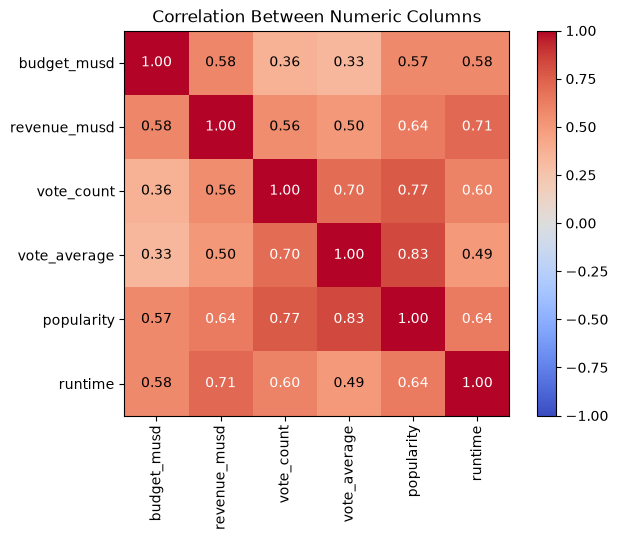

In [30]:
visualize.plot_correlations(df)

**Observation:** All numeric columns are positively correlated, with the strongest link between popularity and rating (0.83). Budget has only a moderate link with revenue (0.58) and a weak one with rating (0.33).

### Step 3: KPI Implementation & Analysis
#### Identify the Best/Worst Performing Movies
> `analysis.rank_movies()` streamlines the ranking operations. It ranks movies with a Spark window function, so tied movies share a rank, and uses the User-Defined Function (UDF) `analysis.format_musd()` to add a readable label (e.g. `$2.94B`) to the money rankings.
>
> A Python UDF runs row by row in a separate Python process, which is much slower than Spark's built-in functions. It is only used here to format the few rows a ranking returns; everything else uses built-in functions.

First, add the profit and ROI columns:

In [31]:
df = analysis.add_profit_and_roi(df)
df.select("title", "budget_musd", "revenue_musd", "profit_musd", "roi").limit(5)

title,budget_musd,revenue_musd,profit_musd,roi
Furious 7,190.0,1515.4,1325.4,7.98
Black Panther,200.0,1349.93,1149.93,6.75
Avengers: Endgame,356.0,2942.19,2586.19,8.26
Jurassic World: Fallen Kingdom,170.0,1310.47,1140.47,7.71
Avatar,237.0,2923.71,2686.71,12.34


1. Filter and rank movies based on:
    - Highest Revenue

In [32]:
analysis.rank_movies(df, "revenue_musd", top_n=5)

title,revenue_musd,rank,label
Avengers: Endgame,2942.19,1,$2.94B
Avatar,2923.71,2,$2.92B
Titanic,2264.16,3,$2.26B
Star Wars: The Force Awakens,2068.22,4,$2.07B
Avengers: Infinity War,2052.42,5,$2.05B


**Observation:** *Avengers: Endgame* (\$2.94B) and *Avatar* (\$2.92B) are almost tied for the highest revenue, well ahead of *Titanic* in third (\$2.26B).

- Highest Budget

In [33]:
analysis.rank_movies(df, "budget_musd", top_n=5)

title,budget_musd,rank,label
Avengers: Endgame,356.0,1,$356.0M
Avengers: Infinity War,300.0,2,$300.0M
Star Wars: The Last Jedi,300.0,2,$300.0M
The Lion King,260.0,4,$260.0M
Star Wars: The Force Awakens,245.0,5,$245.0M


**Observation:** *Avengers: Infinity War* and *Star Wars: The Last Jedi* both had a \$300M budget, so they share 2nd place and the next movie is ranked 4th.

- Highest Profit (Revenue - Budget)

In [34]:
analysis.rank_movies(df, "profit_musd", top_n=5)

title,profit_musd,rank,label
Avatar,2686.71,1,$2.69B
Avengers: Endgame,2586.19,2,$2.59B
Titanic,2064.16,3,$2.06B
Star Wars: The Force Awakens,1823.22,4,$1.82B
Avengers: Infinity War,1752.42,5,$1.75B


- Lowest Profit (Revenue - Budget)

In [35]:
analysis.rank_movies(df, "profit_musd", ascending=True, top_n=5)

title,profit_musd,rank,label
Star Wars: The Last Jedi,1034.41,1,$1.03B
Incredibles 2,1043.23,2,$1.04B
Beauty and the Beast,1106.12,3,$1.11B
Frozen,1124.22,4,$1.12B
Jurassic World: Fallen Kingdom,1140.47,5,$1.14B


**Observation:** Even the least profitable movie, *Star Wars: The Last Jedi*, made over \$1 billion in profit. No movie in this dataset lost money.

- Highest ROI (Revenue / Budget) — only movies with Budget ≥ 10M

In [36]:
budget_10m = analysis.filter_min_budget(df)
analysis.rank_movies(budget_10m, "roi", top_n=5)

title,roi,rank
Avatar,12.34,1
Titanic,11.32,2
Jurassic World,11.14,3
Harry Potter and the Deathly Hallows: Part 2,10.73,4
Frozen II,9.69,5


- Lowest ROI — only movies with Budget ≥ 10M

In [37]:
analysis.rank_movies(budget_10m, "roi", ascending=True, top_n=5)

title,roi,rank
Star Wars: The Last Jedi,4.45,1
Avengers: Age of Ultron,5.98,2
Incredibles 2,6.22,3
The Lion King,6.39,4
Black Panther,6.75,5


**Observation:** *Avatar* has both the highest profit (\$2.69B) and the highest ROI (12.3x its budget). The lowest ROI, *Star Wars: The Last Jedi*, still earned 4.45x its budget.

- Most Voted Movies

In [38]:
analysis.rank_movies(df, "vote_count", top_n=5)

title,vote_count,rank
The Avengers,40248,1
Avatar,34952,2
Avengers: Infinity War,33317,3
Avengers: Endgame,29199,4
Titanic,28005,5


- Highest Rated Movies — only movies with ≥ 10 votes

In [39]:
votes_10 = analysis.filter_min_votes(df)
analysis.rank_movies(votes_10, "vote_average", top_n=5)

title,vote_average,rank
Avengers: Endgame,8.247,1
Avengers: Infinity War,8.246,2
The Avengers,8.084,3
Harry Potter and the Deathly Hallows: Part 2,8.082,4
Titanic,7.901,5


- Lowest Rated Movies — only movies with ≥ 10 votes

In [40]:
analysis.rank_movies(votes_10, "vote_average", ascending=True, top_n=5)

title,vote_average,rank
Jurassic World: Fallen Kingdom,6.52,1
Jurassic World,6.704,2
Star Wars: The Last Jedi,6.73,3
Beauty and the Beast,6.973,4
The Lion King,7.089,5


- Most Popular Movies

In [41]:
analysis.rank_movies(df, "popularity", top_n=5)

title,popularity,rank
Avengers: Endgame,68.2804,1
Avengers: Infinity War,56.2192,2
The Avengers,43.186,3
Avengers: Age of Ultron,36.6838,4
Avatar,36.4465,5


**Observation:** The Avengers movies dominate the audience rankings: *The Avengers* has the most votes, the four most popular movies are all Avengers films, and *Avengers: Endgame* and *Infinity War* are the two highest-rated movies (8.25).

#### Advanced Movie Filtering & Search Queries
2. Filter the dataset for specific queries:
    - **Search 1:** Find the best-rated Science Fiction Action movies starring Bruce Willis (sorted by Rating — highest to lowest)

The searches split the `|`-separated columns into arrays and check for an exact match with `array_contains()`, so a search for "Bruce Willis" can't accidentally match a different name that contains it.

In [42]:
analysis.search_bruce_willis(df).select("title", "genres", "vote_average")

title,genres,vote_average


**Observation:** There are no movies starring Bruce Willis among the movies in the data.

- **Search 2:** Find movies starring Uma Thurman, directed by Quentin Tarantino (sorted by runtime — shortest to longest)

In [43]:
analysis.search_uma_thurman_tarantino(df).select("title", "director", "runtime")

title,director,runtime


**Observation:** There are no movies starring Uma Thurman among the movies in the data.

#### Franchise vs. Standalone Movie Performance
3. Compare movie franchises (`belongs_to_collection`) vs. standalone movies in terms of:
    - Mean Revenue
    - Median ROI
    - Mean Budget Raised
    - Mean Popularity
    - Mean Rating

The median uses Spark's `median()`, which averages the two middle values like Pandas does. `percentile_approx()` would instead return one of the two values, which gives a different answer for a group of 2 movies.

In [44]:
analysis.franchise_vs_standalone(df)

movie_type,movie_count,mean_revenue_musd,median_roi,mean_budget_musd,mean_popularity,mean_rating
Franchise,16,1691.7,7.85,218.0,27.91,7.39
Standalone,2,1765.14,9.62,180.0,26.95,7.44


**Observation:** Franchise movies had bigger budgets (\$218M vs. \$180M on average) and slightly higher popularity. Standalone movies had slightly higher mean revenue and median ROI, but with only 2 standalone movies (*Titanic* and *Beauty and the Beast*) this comparison isn't conclusive.

#### Most Successful Franchises & Directors
4. Find the **Most Successful Movie Franchises** based on:
    - Total number of movies in franchise
    - Total & Mean Budget
    - Total & Mean Revenue
    - Mean Rating

In [45]:
franchises = analysis.franchise_summary(df)
franchises

belongs_to_collection,movie_count,total_budget_musd,mean_budget_musd,total_revenue_musd,mean_revenue_musd,mean_rating
The Avengers Collection,4,1111.0,277.75,7918.83,1979.71,7.96
Star Wars Collection,2,545.0,272.5,3402.63,1701.32,6.98
Jurassic Park Collection,2,320.0,160.0,2982.01,1491.01,6.61
Avatar Collection,1,237.0,237.0,2923.71,2923.71,7.61
Frozen Collection,2,300.0,150.0,2727.9,1363.95,7.23
The Lion King (Reboot) Collection,1,260.0,260.0,1662.02,1662.02,7.09
The Fast and the Furious Collection,1,190.0,190.0,1515.4,1515.4,7.21
Black Panther Collection,1,200.0,200.0,1349.93,1349.93,7.36
Harry Potter Collection,1,125.0,125.0,1341.51,1341.51,8.08
The Incredibles Collection,1,200.0,200.0,1243.23,1243.23,7.45


**Observation:** The Avengers Collection is the most successful franchise, with 4 movies, \$7.9 billion in total revenue, and the highest mean rating of any franchise with more than one movie (7.96).

In [46]:
# The same table sorted by a different metric, e.g. number of movies
franchises.orderBy(F.desc("movie_count"), F.desc("total_revenue_musd"))

belongs_to_collection,movie_count,total_budget_musd,mean_budget_musd,total_revenue_musd,mean_revenue_musd,mean_rating
The Avengers Collection,4,1111.0,277.75,7918.83,1979.71,7.96
Star Wars Collection,2,545.0,272.5,3402.63,1701.32,6.98
Jurassic Park Collection,2,320.0,160.0,2982.01,1491.01,6.61
Frozen Collection,2,300.0,150.0,2727.9,1363.95,7.23
Avatar Collection,1,237.0,237.0,2923.71,2923.71,7.61
The Lion King (Reboot) Collection,1,260.0,260.0,1662.02,1662.02,7.09
The Fast and the Furious Collection,1,190.0,190.0,1515.4,1515.4,7.21
Black Panther Collection,1,200.0,200.0,1349.93,1349.93,7.36
Harry Potter Collection,1,125.0,125.0,1341.51,1341.51,8.08
The Incredibles Collection,1,200.0,200.0,1243.23,1243.23,7.45


5. Find the **Most Successful Directors** based on:
    - Total Number of Movies Directed
    - Total Revenue
    - Mean Rating

In [47]:
directors = analysis.director_summary(df)
directors

director,movie_count,total_revenue_musd,mean_rating
James Cameron,2,5187.87,7.76
Anthony Russo,2,4994.61,8.25
Joe Russo,2,4994.61,8.25
Joss Whedon,2,2924.22,7.68
Chris Buck,2,2727.9,7.23
Jennifer Lee,2,2727.9,7.23
J.J. Abrams,1,2068.22,7.24
Colin Trevorrow,1,1671.54,6.7
Jon Favreau,1,1662.02,7.09
James Wan,1,1515.4,7.21


In [48]:
directors.orderBy(F.desc("mean_rating"), "director")

director,movie_count,total_revenue_musd,mean_rating
Anthony Russo,2,4994.61,8.25
Joe Russo,2,4994.61,8.25
David Yates,1,1341.51,8.08
James Cameron,2,5187.87,7.76
Joss Whedon,2,2924.22,7.68
Brad Bird,1,1243.23,7.45
Ryan Coogler,1,1349.93,7.36
J.J. Abrams,1,2068.22,7.24
Chris Buck,2,2727.9,7.23
Jennifer Lee,2,2727.9,7.23


**Observation:** James Cameron has the highest total revenue (\$5.19B from *Avatar* and *Titanic*). Anthony and Joe Russo, who co-directed both *Avengers: Infinity War* and *Endgame*, have the highest mean rating (8.25).

### Step 4: Data Visualization
Spark does the aggregation for each chart (grouping, averaging, counting), and only the small result is converted to Pandas with `toPandas()` for Matplotlib to draw.

- Revenue vs. Budget Trends

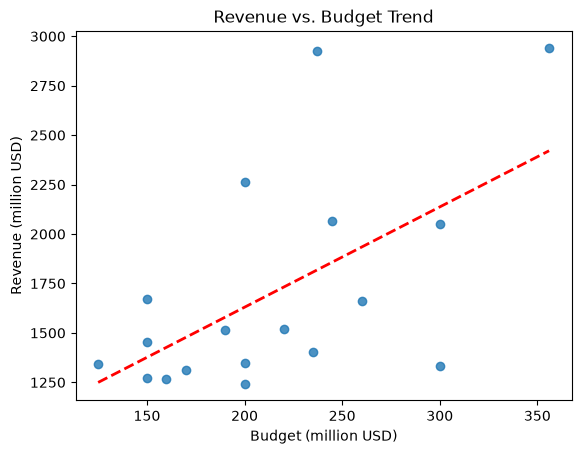

In [49]:
visualize.plot_revenue_vs_budget(df)

**Observation:** Revenue tends to rise with budget, but the points are widely scattered. *Avatar* earned about \$2.9B on a \$237M budget, while *Star Wars: The Last Jedi* earned about \$1.3B on a \$300M budget.

- ROI Distribution by Genre

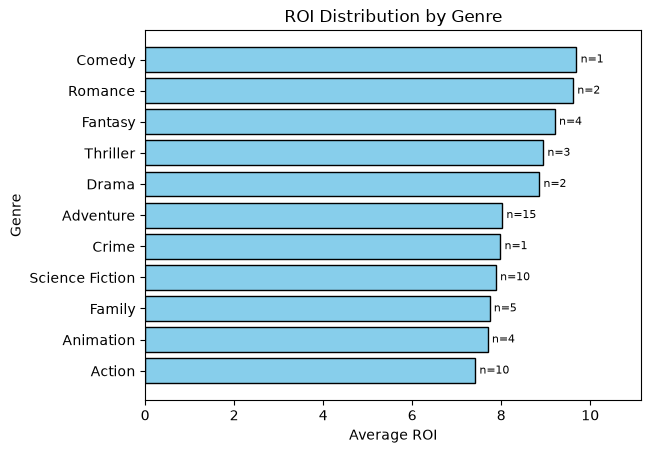

In [50]:
visualize.plot_roi_by_genre(df)

**Observation:** Comedy and Romance have the highest average ROI (about 9.7 and 9.6) and Action the lowest (about 7.4). However, as the labels show, Comedy is based on 1 movie and Romance on 2, so these averages are much less reliable than Action's, which is based on 10.

- Popularity vs. Rating

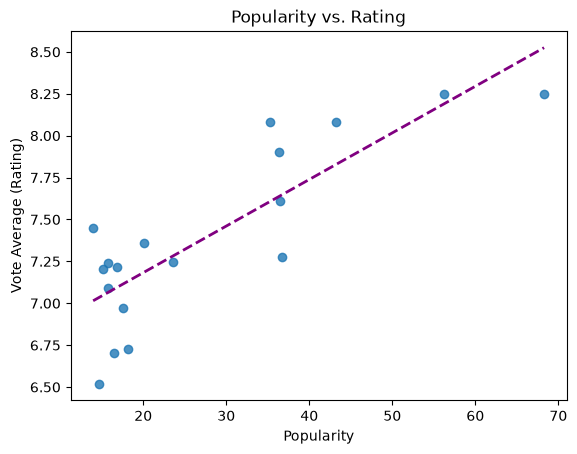

In [51]:
visualize.plot_popularity_vs_rating(df)

**Observation:** More popular movies tend to have higher ratings. The two most popular movies (*Avengers: Endgame* and *Infinity War*) are also rated highest at about 8.25.

- Yearly Trends in Box Office Performance

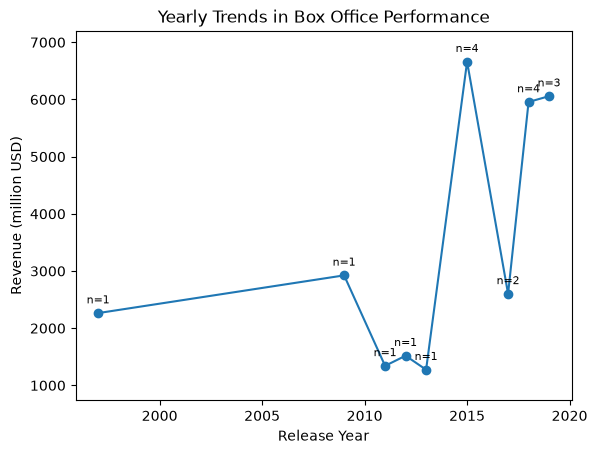

In [52]:
visualize.plot_yearly_revenue(df)

**Observation:** Total revenue peaks in 2015 (about \$6.7B) and 2018–2019 (about \$6B). The movie counts on the chart show why: 4 movies were released in 2015 and 2018, and 3 in 2019, against 1 in most other years. The chart reflects how many movies came out each year more than a real box office trend.

- Comparison of Franchise vs. Standalone Success

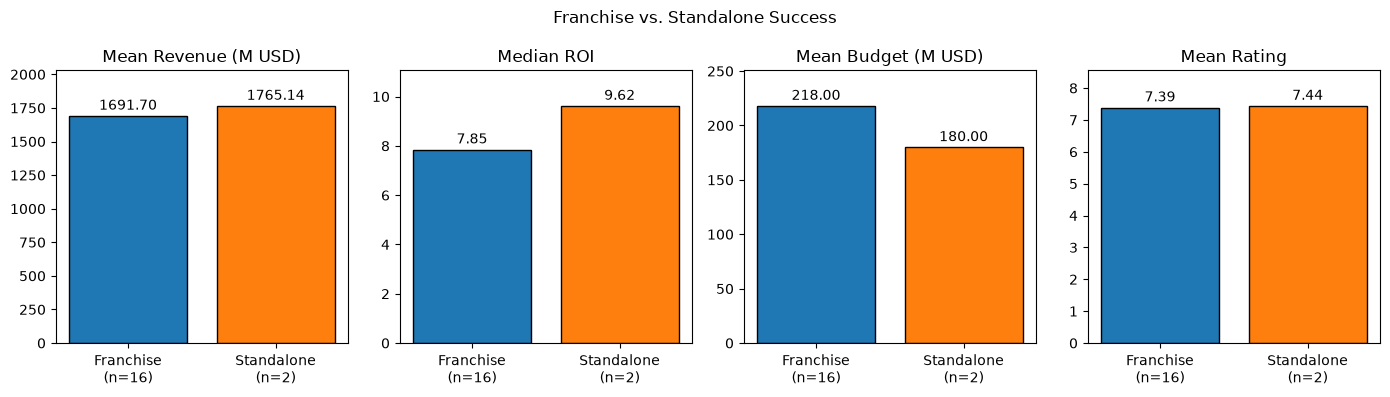

In [53]:
visualize.plot_franchise_vs_standalone(df)

**Observation:** Standalone movies are slightly ahead on mean revenue, median ROI and mean rating, while franchise movies had bigger budgets. The differences are small, and the standalone group has only 2 movies, so the chart does not show that one type is more successful than the other.

### Pandas vs. Spark: what changed
This analysis was first built with Pandas. Rebuilding it with Spark gave the same results, with these differences in how the work is done:

- **Built-in functions instead of Python loops.** Nested JSON columns are flattened with Spark column expressions (`concat_ws`, `filter`, `size`) instead of Python functions applied row by row, so the work runs in parallel inside Spark.
- **Explicit schema.** The raw data is read with a defined schema instead of inferring types, which is faster and catches values of the wrong type.
- **Lazy evaluation and caching.** Spark builds a plan and only runs it when a result is needed; the clean data is cached because every later step reuses it.
- **No row index.** Spark DataFrames have no index to reset.
- **Ties share a rank.** Rankings use a window function, so tied movies share a rank instead of one being cut off.
- **Empty lists become null.** A movie with no genres gets null instead of an empty string, so it counts as missing data.
- **Spark aggregates, Matplotlib draws.** Charts are aggregated in Spark and only the small results are converted to Pandas.
- **Fewer shuffle partitions.** `spark.sql.shuffle.partitions` is set to 4 instead of the default 200, which suits a dataset of 18 movies.

In [54]:
# Stop Spark when you're done with the notebook
spark.stop()